# <center >Hybrid Search RAG | Chapter 1 </center>
## What Is Hybrid Search RAG? — Deep Theory + Visual + Practical Notebook

> **Goal of this notebook:** You should be able to study Chapter 1 primarily from this notebook without needing to reread the long theory article.

This notebook deliberately mixes:

- **Theory in simple language**
- **ASCII architecture diagrams**
- **Matplotlib visual diagrams**
- **Small examples before complex examples**
- **Instrumented Python code** with print statements showing internal flow
- **Sparse retrieval experiments**
- **Dense retrieval experiments**
- **Hybrid fusion experiments**
- **Failure cases**
- **Debugging strategy**
- **Interview questions and revision notes**

---

## What you should understand by the end

You should be able to explain, from first principles:

1. What RAG is and why retrieval is needed.
2. What a **query**, **document**, **chunk**, **index**, and **Top-K** mean.
3. What **sparse / lexical retrieval** means.
4. What **dense / semantic retrieval** means.
5. Why sparse search is strong for exact words, IDs, codes, and article numbers.
6. Why dense search is strong for meaning, synonyms, and paraphrases.
7. Why either retrieval method alone can fail.
8. What Hybrid Search actually combines.
9. What **fusion** does.
10. Why **reranking** is separate from fusion.
11. Why retrieval quality can become the bottleneck of a RAG system.
12. How to debug a Hybrid RAG pipeline stage by stage.


# 0. The Big Picture Before Any Code

Suppose your organization has thousands of documents:

```text
Policies        Regulations        Manuals
   │                 │                │
   └─────────────────┼────────────────┘
                     ↓
               Knowledge Base
```

A user asks:

```text
"What are the supplier obligations under REACH Article 33?"
```

An LLM should not be expected to magically know which internal or current document contains the answer. A RAG system first **retrieves evidence**, then asks the LLM to answer using that evidence.

```text
User Question
      │
      ▼
Find Relevant Evidence   ← retrieval
      │
      ▼
Question + Evidence
      │
      ▼
     LLM
      │
      ▼
Grounded Answer
```

### One sentence to remember

> **RAG = Retrieve relevant external information first, then generate an answer using it.**


## 0.1 Basic Terms | Do Not Skip These

These words will appear throughout the entire Hybrid Search course.

| Term | Meaning | Tiny example |
|---|---|---|
| **Query** | What the user searches or asks | `REACH Article 33` |
| **Document** | A source file or logical record | a 50-page regulation PDF |
| **Chunk** | A smaller piece cut from a document | one paragraph / 500 tokens |
| **Index** | A data structure prepared for fast search | TF-IDF matrix, BM25 index, vector DB |
| **Retriever** | Component that finds likely relevant chunks | BM25 or vector search |
| **Top-K** | Return the best K matches | Top-5 = best five chunks |
| **Score** | Number representing retrieval relevance | similarity = 0.82 |
| **Candidate** | A retrieved item not yet finally accepted | Top-20 before reranking |
| **Fusion** | Combine results from multiple retrievers | sparse + dense |
| **Reranking** | Re-evaluate candidates more carefully | Top-20 → Top-5 |
| **Context** | Retrieved text finally sent to the LLM | 5 best chunks |

### Important distinction

A **document** can be huge. Search systems often retrieve **chunks**, not entire documents.


# 1. RAG Architecture | Visual Mental Model

A common RAG system has two broad phases.

### A. Offline / ingestion phase

```text
Documents
   ↓
Parsing
   ↓
Chunking
   ↓
Indexing
   ├───────────────┐
   ↓               ↓
Sparse Index    Vector Index
```

### B. Online / query phase

```text
User Query
    ↓
Retrieval
    ↓
Relevant Chunks
    ↓
LLM Context
    ↓
Answer
```

Hybrid Search mainly improves the **retrieval** portion.


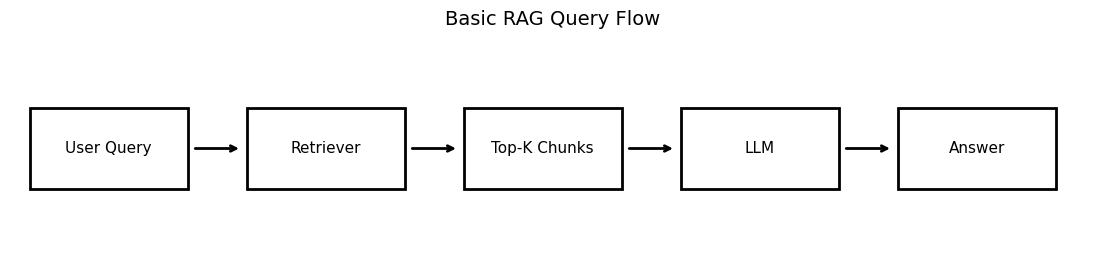

In [8]:
# Import matplotlib so we can draw a visual pipeline.
import matplotlib.pyplot as plt

# 1. Remove display limits for rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# Optional: Prevent cell content/long text from cutting off
pd.set_option('display.max_colwidth', None)

# Import Rectangle for drawing boxes.
from matplotlib.patches import Rectangle

def draw_flow_diagram(labels, title):
    """Draw a simple left-to-right flow diagram."""

    # Create a wide figure.
    fig, ax = plt.subplots(figsize=(14, 3))

    # Hide normal axes because this is a conceptual diagram.
    ax.axis("off")

    # Set drawing limits.
    ax.set_xlim(0, len(labels) * 2.2)
    ax.set_ylim(0, 2)

    # Loop through each step.
    for i, label in enumerate(labels):
        # Calculate the x coordinate of this box.
        x = i * 2.2 + 0.2

        # Draw a rectangle.
        box = Rectangle((x, 0.65), 1.6, 0.7, fill=False, linewidth=2)
        ax.add_patch(box)

        # Write text inside the box.
        ax.text(x + 0.8, 1.0, label, ha="center", va="center", fontsize=11)

        # Draw an arrow to the next box.
        if i < len(labels) - 1:
            ax.annotate(
                "",
                xy=(x + 2.15, 1.0),
                xytext=(x + 1.65, 1.0),
                arrowprops=dict(arrowstyle="->", linewidth=2),
            )

    # Add title.
    ax.set_title(title, fontsize=14)

    # Display the diagram.
    plt.show()


# Draw the basic RAG query-time pipeline.
draw_flow_diagram(
    ["User Query", "Retriever", "Top-K Chunks", "LLM", "Answer"],
    "Basic RAG Query Flow",
)

## What just happened in the diagram?

1. The **user query** is the search question.
2. The **retriever** searches previously indexed data.
3. It returns a small **Top-K** set instead of every document.
4. Those chunks become **context** for the LLM.
5. The LLM generates the final response.

### Why Top-K exists

If you have 1,000,000 chunks, you cannot send all of them to the LLM. Retrieval reduces:

```text
1,000,000 chunks
      ↓
Top 20 candidates
      ↓
Top 5 final chunks
      ↓
LLM
```

So retrieval is a **search-space reduction problem**.


# 2. Why Hybrid Search Exists

There are two major ways we will retrieve text.

```text
                   User Query
                       │
             ┌─────────┴─────────┐
             │                   │
             ▼                   ▼
       Sparse Search       Dense Search
       words / terms       meaning / vectors
             │                   │
             └─────────┬─────────┘
                       ▼
                    Fusion
                       ↓
                 Better Candidates
```

The key idea is not that one retriever is "bad" and another is "good".

> **They observe different relevance signals.**

Sparse search asks roughly:

> "Do the query words appear in this document?"

Dense search asks roughly:

> "Does this document mean something similar to the query?"


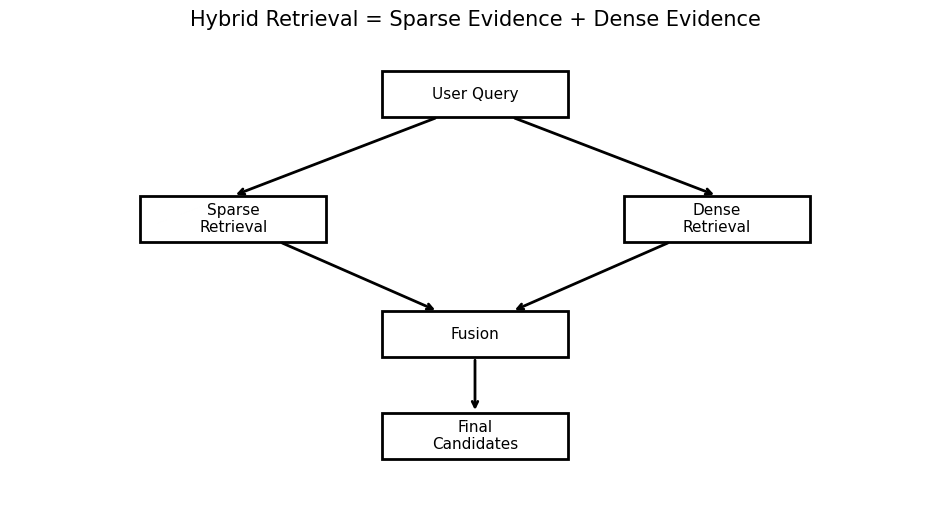

In [6]:
# Draw the Hybrid Search architecture visually.
fig, ax = plt.subplots(figsize=(12, 6))
ax.axis("off")
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)

# Define box positions.
boxes = {
    "User Query": (4, 8.2),
    "Sparse\nRetrieval": (1.4, 5.5),
    "Dense\nRetrieval": (6.6, 5.5),
    "Fusion": (4, 3.0),
    "Final\nCandidates": (4, 0.8),
}

# Draw all boxes.
for label, (x, y) in boxes.items():
    rect = Rectangle((x, y), 2, 1, fill=False, linewidth=2)
    ax.add_patch(rect)
    ax.text(x + 1, y + 0.5, label, ha="center", va="center", fontsize=11)

# Draw query → sparse.
ax.annotate("", xy=(2.4, 6.5), xytext=(4.6, 8.2), arrowprops=dict(arrowstyle="->", linewidth=2))

# Draw query → dense.
ax.annotate("", xy=(7.6, 6.5), xytext=(5.4, 8.2), arrowprops=dict(arrowstyle="->", linewidth=2))

# Draw sparse → fusion.
ax.annotate("", xy=(4.6, 4.0), xytext=(2.9, 5.5), arrowprops=dict(arrowstyle="->", linewidth=2))

# Draw dense → fusion.
ax.annotate("", xy=(5.4, 4.0), xytext=(7.1, 5.5), arrowprops=dict(arrowstyle="->", linewidth=2))

# Draw fusion → final candidates.
ax.annotate("", xy=(5.0, 1.8), xytext=(5.0, 3.0), arrowprops=dict(arrowstyle="->", linewidth=2))

ax.set_title("Hybrid Retrieval = Sparse Evidence + Dense Evidence", fontsize=15)
plt.show()


# 3. Sparse Retrieval From First Principles

Sparse retrieval is usually called:

- lexical retrieval
- keyword retrieval
- term-based retrieval

A production Hybrid Search system often uses **BM25** for the sparse side. In this first chapter we use **TF-IDF** because it is easier to inspect. BM25 gets its own later chapter.

### Basic intuition

Suppose the query is:

```text
REACH Article 33
```

A document containing these exact terms should receive strong lexical evidence.

But query:

```text
Why can't users log in?
```

and document:

```text
Authentication failure caused by invalid credentials.
```

have similar meaning but weak word overlap. That is where sparse retrieval can struggle.


## 3.1 Why is it called "sparse"?

Imagine your entire vocabulary has 100,000 possible terms.

A document contains only 100 of them.

Its conceptual vector may look like:

```text
[0, 0, 0, 4.2, 0, 0, 7.1, 0, 0, 0, ...]
```

Most positions are **zero**.

That is a **sparse vector**.

You do **not** need to memorize this yet. Just remember:

```text
Sparse vector → mostly zeros → usually term/vocabulary based
```


# 4. Create Our Tiny Enterprise Corpus

We intentionally mix multiple query types:

- exact legal references
- semantic legal descriptions
- error codes
- login/support language
- product codes
- product descriptions

This allows us to observe the strengths and weaknesses of each retriever.


In [9]:
# Import NumPy for numerical calculations.
import numpy as np

# Import pandas for readable tables.
import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Import TF-IDF for our educational sparse retriever.
from sklearn.feature_extraction.text import TfidfVectorizer

# Import cosine similarity for vector comparison.
from sklearn.metrics.pairwise import cosine_similarity

# Import display so DataFrames render nicely inside Jupyter.
from IPython.display import display


# Create a deliberately mixed corpus.
documents = [
    {
        "id": "D1",
        "type": "legal_exact",
        "text": "REACH Regulation EC 1907/2006 governs chemical substances."
    },
    {
        "id": "D2",
        "type": "legal_semantic",
        "text": "European rules control hazardous substances used in products."
    },
    {
        "id": "D3",
        "type": "legal_exact",
        "text": "REACH Article 33 requires suppliers to communicate information about substances of very high concern, also called SVHCs."
    },
    {
        "id": "D4",
        "type": "product_regulation",
        "text": "RoHS restricts certain hazardous substances in electrical and electronic equipment."
    },
    {
        "id": "D5",
        "type": "error_code",
        "text": "Error code E401 indicates an authentication failure caused by invalid or expired credentials."
    },
    {
        "id": "D6",
        "type": "support_semantic",
        "text": "Users who cannot sign in should verify credentials and reset their password if necessary."
    },
    {
        "id": "D7",
        "type": "product_code",
        "text": "Siemens product 6ES7513-1AL02-0AB0 is an industrial automation component."
    },
    {
        "id": "D8",
        "type": "product_semantic",
        "text": "Industrial automation hardware can be selected based on controller capacity and communication requirements."
    },
]

# Convert to a DataFrame for easier viewing.
df = pd.DataFrame(documents)

# Print an explanation before displaying the data.
print("We created", len(df), "documents.")
print("Each row acts like a tiny searchable document/chunk.\n")

# Show the corpus.
display(df)

We created 8 documents.
Each row acts like a tiny searchable document/chunk.



,id,type,text
0,D1,legal_exact,REACH Regulation EC 1907/2006 governs chemical substances.
1,D2,legal_semantic,European rules control hazardous substances used in products.
2,D3,legal_exact,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, also called SVHCs."
3,D4,product_regulation,RoHS restricts certain hazardous substances in electrical and electronic equipment.
4,D5,error_code,Error code E401 indicates an authentication failure caused by invalid or expired credentials.
5,D6,support_semantic,Users who cannot sign in should verify credentials and reset their password if necessary.
6,D7,product_code,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation component.
7,D8,product_semantic,Industrial automation hardware can be selected based on controller capacity and communication requirements.


# 5. Tokenization | The First Hidden Step in Keyword Search

Before a lexical system can match words, text is usually broken into **tokens**.

For example:

```text
"REACH Article 33 requires suppliers"
```

might become roughly:

```text
["reach", "article", "33", "requires", "suppliers"]
```

A **token** is simply a unit the search system works with. Often it resembles a word, but tokenization rules can be more complex.

This matters because product codes such as:

```text
6ES7513-1AL02-0AB0
```

may be split differently depending on the tokenizer.


In [10]:
# Import regular expressions for a transparent toy tokenizer.
import re


def simple_tokenize(text):
    """A tiny tokenizer used only to make tokenization visible."""

    # Convert text to lowercase so REACH and reach are treated similarly.
    lowered = text.lower()

    # Extract sequences of letters and numbers.
    tokens = re.findall(r"[a-z0-9]+", lowered)

    # Print every internal stage.
    print("ORIGINAL TEXT :", text)
    print("LOWERCASED    :", lowered)
    print("TOKENS        :", tokens)

    return tokens


# Demonstrate a legal phrase.
print("--- Legal phrase tokenization ---")
simple_tokenize("REACH Article 33 requires suppliers")

print("\n--- Product code tokenization ---")
simple_tokenize("6ES7513-1AL02-0AB0")


--- Legal phrase tokenization ---
ORIGINAL TEXT : REACH Article 33 requires suppliers
LOWERCASED    : reach article 33 requires suppliers
TOKENS        : ['reach', 'article', '33', 'requires', 'suppliers']

--- Product code tokenization ---
ORIGINAL TEXT : 6ES7513-1AL02-0AB0
LOWERCASED    : 6es7513-1al02-0ab0
TOKENS        : ['6es7513', '1al02', '0ab0']


['6es7513', '1al02', '0ab0']

## Why this basic step matters

If the user searches an exact code but your tokenizer breaks it in an unexpected way, search quality can drop.

Production search engines therefore often configure special analyzers for:

```text
Product IDs
Regulation IDs
Chemical IDs
Versions
URLs
Email addresses
Error codes
```

We will go much deeper into inverted indexes and tokenization in later chapters.


# 6. Build a Sparse TF-IDF Index

### What does "fit" mean here?

When we run:

```python
vectorizer.fit_transform(corpus)
```

TF-IDF does two broad things:

1. Learns the vocabulary found in our documents.
2. Converts each document into a numerical sparse vector.

The result is a matrix:

```text
rows    = documents
columns = learned terms
values  = term weights
```


In [12]:
# Extract raw text from the DataFrame.
corpus = df["text"].tolist()

print(corpus)

# Create the TF-IDF vectorizer.
tfidf_vectorizer = TfidfVectorizer(lowercase=True)
print(tfidf_vectorizer)

# Learn the vocabulary and convert every document into a sparse matrix.
tfidf_document_matrix = tfidf_vectorizer.fit_transform(corpus)
print(tfidf_document_matrix)

# Retrieve the learned vocabulary terms.
feature_names = np.array(tfidf_vectorizer.get_feature_names_out())

# Print the internal structure.
print("===== TF-IDF INDEX BUILD =====")
print("Number of documents       :", tfidf_document_matrix.shape[0])
print("Number of vocabulary terms:", tfidf_document_matrix.shape[1])
print("Matrix shape              :", tfidf_document_matrix.shape)
print("Matrix Python type        :", type(tfidf_document_matrix))
print("\nFirst 25 learned terms:")
print(feature_names[:25])

# Show how sparse the matrix is.
non_zero = tfidf_document_matrix.nnz
total_cells = tfidf_document_matrix.shape[0] * tfidf_document_matrix.shape[1]
print("\nNon-zero matrix cells:", non_zero)
print("Total possible cells  :", total_cells)
print("Fraction non-zero      :", round(non_zero / total_cells, 4))


['REACH Regulation EC 1907/2006 governs chemical substances.', 'European rules control hazardous substances used in products.', 'REACH Article 33 requires suppliers to communicate information about substances of very high concern, also called SVHCs.', 'RoHS restricts certain hazardous substances in electrical and electronic equipment.', 'Error code E401 indicates an authentication failure caused by invalid or expired credentials.', 'Users who cannot sign in should verify credentials and reset their password if necessary.', 'Siemens product 6ES7513-1AL02-0AB0 is an industrial automation component.', 'Industrial automation hardware can be selected based on controller capacity and communication requirements.']
TfidfVectorizer()
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 93 stored elements and shape (8, 80)>
  Coords	Values
  (0, 58)	0.3144269443667412
  (0, 59)	0.37517620981142785
  (0, 32)	0.37517620981142785
  (0, 1)	0.37517620981142785
  (0, 3)	0.37517620981142785
  

### Interpreting the matrix shape

If you see:

```text
(8, 57)
```

that means:

```text
8 rows      → 8 documents
57 columns  → 57 vocabulary features
```

Each document is represented using the **same vocabulary space** so the query can later be compared with every document.


In [13]:
# Inspect one document vector in human-readable form.
doc_index = 2

doc_vector = tfidf_document_matrix[doc_index]

# Find only the non-zero positions.
non_zero_indices = doc_vector.nonzero()[1]

print("DOCUMENT:")
print(df.iloc[doc_index]["text"])
print("\nNon-zero TF-IDF features for this document:")

# Print each visible term and its weight.
for idx in non_zero_indices:
    term = feature_names[idx]
    weight = doc_vector[0, idx]
    print(f"  {term:<18} -> {weight:.4f}")


DOCUMENT:
REACH Article 33 requires suppliers to communicate information about substances of very high concern, also called SVHCs.

Non-zero TF-IDF features for this document:
  reach              -> 0.2088
  substances         -> 0.1580
  article            -> 0.2492
  33                 -> 0.2492
  requires           -> 0.2492
  suppliers          -> 0.2492
  to                 -> 0.2492
  communicate        -> 0.2492
  information        -> 0.2492
  about              -> 0.2492
  of                 -> 0.2492
  very               -> 0.2492
  high               -> 0.2492
  concern            -> 0.2492
  also               -> 0.2492
  called             -> 0.2492
  svhcs              -> 0.2492


# 7. Sparse Search — Show Every Important Internal Step

A query goes through roughly:

```text
Query text
    ↓
Query vector
    ↓
Compare with document vectors
    ↓
Similarity score for every document
    ↓
Sort scores
    ↓
Top-K
```

We will deliberately print each stage so the retrieval process is not a black box.


In [14]:
def sparse_search_verbose(query, top_k=5, show_all_scores=True):
    """Run sparse retrieval while exposing the internal flow."""

    print("=" * 100)
    print("SPARSE RETRIEVAL")
    print("=" * 100)
    print("1) RAW QUERY:")
    print("  ", query)

    # Convert the query into the same TF-IDF vocabulary space.
    query_vector = tfidf_vectorizer.transform([query])

    print("\n2) QUERY VECTOR SHAPE:")
    print("  ", query_vector.shape)

    # Find visible non-zero query features.
    query_non_zero = query_vector.nonzero()[1]

    print("\n3) NON-ZERO QUERY FEATURES:")
    if len(query_non_zero) == 0:
        print("   No query terms exist in the learned vocabulary.")
    else:
        for idx in query_non_zero:
            print(f"   {feature_names[idx]:<18} -> {query_vector[0, idx]:.4f}")

    # Compare query vector with every document vector.
    scores = cosine_similarity(query_vector, tfidf_document_matrix).flatten()

    if show_all_scores:
        print("\n4) RAW SIMILARITY SCORE FOR EVERY DOCUMENT:")
        for doc_id, score in zip(df["id"], scores):
            print(f"   {doc_id}: {score:.4f}")

    # Sort highest score first.
    ranked_indices = np.argsort(scores)[::-1]

    print("\n5) RANKING ORDER:")
    for rank, idx in enumerate(ranked_indices[:top_k], start=1):
        print(f"   Rank {rank}: {df.iloc[idx]['id']} | score={scores[idx]:.4f}")

    # Build a readable result table.
    results = df.iloc[ranked_indices[:top_k]].copy()
    results["sparse_score"] = scores[ranked_indices[:top_k]]

    print("\n6) FINAL TOP-K RESULTS:")
    display(results[["id", "type", "text", "sparse_score"]])

    return results[["id", "type", "text", "sparse_score"]], scores


## 7.1 Experiment — Exact Legal Reference

Exact terms should help sparse retrieval.


In [15]:
sparse_legal_results, sparse_legal_scores = sparse_search_verbose(
    "REACH Article 33",
    top_k=5,
)


SPARSE RETRIEVAL
1) RAW QUERY:
   REACH Article 33

2) QUERY VECTOR SHAPE:
   (1, 80)

3) NON-ZERO QUERY FEATURES:
   33                 -> 0.6083
   article            -> 0.6083
   reach              -> 0.5098

4) RAW SIMILARITY SCORE FOR EVERY DOCUMENT:
   D1: 0.1603
   D2: 0.0000
   D3: 0.4096
   D4: 0.0000
   D5: 0.0000
   D6: 0.0000
   D7: 0.0000
   D8: 0.0000

5) RANKING ORDER:
   Rank 1: D3 | score=0.4096
   Rank 2: D1 | score=0.1603
   Rank 3: D8 | score=0.0000
   Rank 4: D7 | score=0.0000
   Rank 5: D6 | score=0.0000

6) FINAL TOP-K RESULTS:


,id,type,text,sparse_score
2,D3,legal_exact,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, also called SVHCs.",0.409638
0,D1,legal_exact,REACH Regulation EC 1907/2006 governs chemical substances.,0.160299
7,D8,product_semantic,Industrial automation hardware can be selected based on controller capacity and communication requirements.,0.000000
6,D7,product_code,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation component.,0.000000
5,D6,support_semantic,Users who cannot sign in should verify credentials and reset their password if necessary.,0.000000


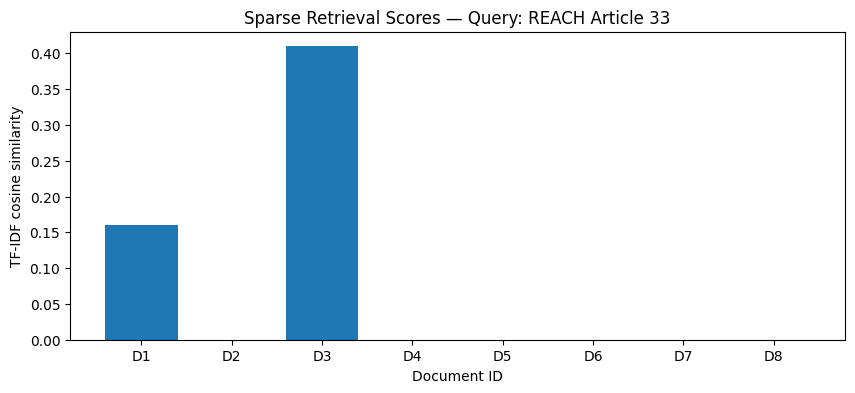

In [16]:
# Visualize sparse scores for the exact legal query.
plt.figure(figsize=(10, 4))
plt.bar(df["id"], sparse_legal_scores)
plt.xlabel("Document ID")
plt.ylabel("TF-IDF cosine similarity")
plt.title("Sparse Retrieval Scores — Query: REACH Article 33")
plt.show()

### Interpretation

Sparse retrieval is strong here because terms such as:

```text
REACH
Article
33
```

occur explicitly in the correct document.

This is one of sparse retrieval's biggest strengths:

> **Exact lexical evidence remains visible and measurable.**


## 7.2 Experiment — Exact Error Code

`E401` has very little human-language meaning by itself. But it is a highly valuable exact identifier.


In [17]:
sparse_error_results, sparse_error_scores = sparse_search_verbose(
    "E401",
    top_k=5,
)


SPARSE RETRIEVAL
1) RAW QUERY:
   E401

2) QUERY VECTOR SHAPE:
   (1, 80)

3) NON-ZERO QUERY FEATURES:
   e401               -> 1.0000

4) RAW SIMILARITY SCORE FOR EVERY DOCUMENT:
   D1: 0.0000
   D2: 0.0000
   D3: 0.0000
   D4: 0.0000
   D5: 0.2839
   D6: 0.0000
   D7: 0.0000
   D8: 0.0000

5) RANKING ORDER:
   Rank 1: D5 | score=0.2839
   Rank 2: D8 | score=0.0000
   Rank 3: D7 | score=0.0000
   Rank 4: D6 | score=0.0000
   Rank 5: D4 | score=0.0000

6) FINAL TOP-K RESULTS:


,id,type,text,sparse_score
4,D5,error_code,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.283927
7,D8,product_semantic,Industrial automation hardware can be selected based on controller capacity and communication requirements.,0.000000
6,D7,product_code,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation component.,0.000000
5,D6,support_semantic,Users who cannot sign in should verify credentials and reset their password if necessary.,0.000000
3,D4,product_regulation,RoHS restricts certain hazardous substances in electrical and electronic equipment.,0.000000


## 7.3 Experiment — Exact Product Code

Product codes are another important enterprise use case.


In [18]:
sparse_product_results, sparse_product_scores = sparse_search_verbose(
    "6ES7513-1AL02-0AB0",
    top_k=5,
)


SPARSE RETRIEVAL
1) RAW QUERY:
   6ES7513-1AL02-0AB0

2) QUERY VECTOR SHAPE:
   (1, 80)

3) NON-ZERO QUERY FEATURES:
   0ab0               -> 0.5774
   1al02              -> 0.5774
   6es7513            -> 0.5774

4) RAW SIMILARITY SCORE FOR EVERY DOCUMENT:
   D1: 0.0000
   D2: 0.0000
   D3: 0.0000
   D4: 0.0000
   D5: 0.0000
   D6: 0.0000
   D7: 0.5739
   D8: 0.0000

5) RANKING ORDER:
   Rank 1: D7 | score=0.5739
   Rank 2: D8 | score=0.0000
   Rank 3: D6 | score=0.0000
   Rank 4: D5 | score=0.0000
   Rank 5: D4 | score=0.0000

6) FINAL TOP-K RESULTS:


,id,type,text,sparse_score
6,D7,product_code,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation component.,0.573945
7,D8,product_semantic,Industrial automation hardware can be selected based on controller capacity and communication requirements.,0.000000
5,D6,support_semantic,Users who cannot sign in should verify credentials and reset their password if necessary.,0.000000
4,D5,error_code,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.000000
3,D4,product_regulation,RoHS restricts certain hazardous substances in electrical and electronic equipment.,0.000000


# 8. Where Sparse Search Can Fail — Vocabulary Mismatch

Consider:

```text
Query:
"Why can't a user log in?"

Document:
"Error code E401 indicates an authentication failure caused by invalid credentials."
```

Humans understand relationships such as:

```text
log in
≈ sign in
≈ authentication
≈ credentials
```

But a lexical retriever mainly sees **tokens**. If words differ too much, the relevant document can receive a weak score.

This problem is called **vocabulary mismatch**.


In [19]:
sparse_semantic_results, sparse_semantic_scores = sparse_search_verbose(
    "Why can't a user log in?",
    top_k=5,
)


SPARSE RETRIEVAL
1) RAW QUERY:
   Why can't a user log in?

2) QUERY VECTOR SHAPE:
   (1, 80)

3) NON-ZERO QUERY FEATURES:
   can                -> 0.8103
   in                 -> 0.5860

4) RAW SIMILARITY SCORE FOR EVERY DOCUMENT:
   D1: 0.0000
   D2: 0.1646
   D3: 0.0000
   D4: 0.1484
   D5: 0.0000
   D6: 0.1187
   D7: 0.0000
   D8: 0.2346

5) RANKING ORDER:
   Rank 1: D8 | score=0.2346
   Rank 2: D2 | score=0.1646
   Rank 3: D4 | score=0.1484
   Rank 4: D6 | score=0.1187
   Rank 5: D7 | score=0.0000

6) FINAL TOP-K RESULTS:


,id,type,text,sparse_score
7,D8,product_semantic,Industrial automation hardware can be selected based on controller capacity and communication requirements.,0.234622
1,D2,legal_semantic,European rules control hazardous substances used in products.,0.164621
3,D4,product_regulation,RoHS restricts certain hazardous substances in electrical and electronic equipment.,0.148445
5,D6,support_semantic,Users who cannot sign in should verify credentials and reset their password if necessary.,0.118694
6,D7,product_code,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation component.,0.000000


### Key lesson

Sparse retrieval is not "bad". It simply observes a different signal.

```text
Sparse strength:
exact words / codes / IDs / rare terms

Sparse weakness:
meaning expressed using different vocabulary
```


# 9. Dense Retrieval From First Principles

Dense retrieval uses **embeddings**.

An embedding is a list of numbers representing text in a learned vector space.

For example, conceptually:

```text
"cannot log in"
       ↓
[0.18, -0.41, 0.73, ...]

"authentication failure"
       ↓
[0.20, -0.39, 0.70, ...]
```

The actual numbers themselves are not meant to be interpreted one-by-one.

The important property is:

> Texts with related meaning should usually be located closer together in embedding space.


## 9.1 Why is it called "dense"?

Unlike a sparse lexical vector where most dimensions are zero, an embedding often looks like:

```text
[0.238, -0.119, 0.842, 0.092, -0.311, ...]
```

Many dimensions contain non-zero floating-point values.

Therefore:

```text
Dense vector → many non-zero values → semantic embedding representation
```


# 10. Cosine Similarity — Explained Before We Use It

Dense search needs a way to compare vectors.

One common metric is **cosine similarity**.

### Intuition

Cosine similarity primarily asks:

> Do these two vectors point in a similar direction?

For normalized vectors:

```text
similar direction  → score near 1
unrelated direction → lower score
```

The mathematical formula is:

\[
\text{cosine}(A,B)=\frac{A\cdot B}{\|A\|\|B\|}
\]

You do **not** need to memorize it yet. First understand it visually.


In [21]:
# Create tiny 2D vectors so cosine similarity can be visualized.
a = np.array([1.0, 0.8])
b = np.array([0.9, 0.7])
c = np.array([-0.2, 1.0])


def cosine_manual(x, y):
    # Dot product measures alignment.
    dot_product = np.dot(x, y)

    # Norm is vector length.
    x_norm = np.linalg.norm(x)
    y_norm = np.linalg.norm(y)

    # Divide alignment by both lengths.
    score = dot_product / (x_norm * y_norm)

    print("x             =", x)
    print("y             =", y)
    print("")
    print("dot product   =", round(dot_product, 4))
    print("||x||         =", round(x_norm, 4))
    print("||y||         =", round(y_norm, 4))
    print("cosine score  =", round(score, 4))

    return score


print("A vs B — similar directions")
cosine_manual(a, b)

print("\nA vs C — less similar directions")
cosine_manual(a, c)


A vs B — similar directions
x             = [1.  0.8]
y             = [0.9 0.7]

dot product   = 1.46
||x||         = 1.2806
||y||         = 1.1402
cosine score  = 0.9999

A vs C — less similar directions
x             = [1.  0.8]
y             = [-0.2  1. ]

dot product   = 0.6
||x||         = 1.2806
||y||         = 1.0198
cosine score  = 0.4594


np.float64(0.45942291887376663)

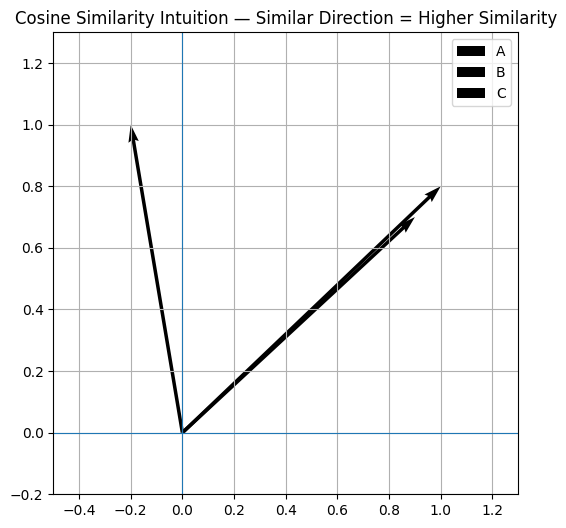

In [22]:
# Visualize the same tiny vectors.
plt.figure(figsize=(6, 6))

# Draw each vector from the origin.
plt.quiver(0, 0, a[0], a[1], angles="xy", scale_units="xy", scale=1, label="A")
plt.quiver(0, 0, b[0], b[1], angles="xy", scale_units="xy", scale=1, label="B")
plt.quiver(0, 0, c[0], c[1], angles="xy", scale_units="xy", scale=1, label="C")

plt.xlim(-0.5, 1.3)
plt.ylim(-0.2, 1.3)
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.grid(True)
plt.legend()
plt.title("Cosine Similarity Intuition — Similar Direction = Higher Similarity")
plt.show()


# 11. Build a Dense Embedding Index

We use `sentence-transformers` only for learning here.

The first time the model is loaded, it may need to download model files.

### What the code will do

```text
Document text
     ↓
Embedding model
     ↓
Dense vector
     ↓
Store vectors
```

At query time:

```text
Query
  ↓
Query embedding
  ↓
Compare against document embeddings
  ↓
Top-K
```


In [ ]:
# If needed, uncomment this once.
# %pip install -q sentence-transformers


In [23]:
# Import the SentenceTransformer embedding class.
from sentence_transformers import SentenceTransformer

# Load a compact educational embedding model.
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

print("Embedding model loaded successfully.")

# Convert every corpus document into an embedding.
document_embeddings = embedding_model.encode(
    corpus,
    normalize_embeddings=True,
)

print("\n===== DENSE INDEX BUILD =====")
print("Number of document embeddings:", document_embeddings.shape[0])
print("Embedding dimensions          :", document_embeddings.shape[1])
print("Embedding matrix shape        :", document_embeddings.shape)

print("\nFirst 10 dimensions of D1:")
print(np.round(document_embeddings[0][:10], 4))


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 103/103 [00:00<00:00, 8855.45it/s]


Embedding model loaded successfully.

===== DENSE INDEX BUILD =====
Number of document embeddings: 8
Embedding dimensions          : 384
Embedding matrix shape        : (8, 384)

First 10 dimensions of D1:
[-0.0213 -0.0231 -0.0046  0.0011  0.0935  0.1286  0.0186  0.1366 -0.0383
  0.0086]


### What does an embedding shape like `(8, 384)` mean?

```text
8   = eight documents
384 = each document is represented by 384 learned numeric dimensions
```

Unlike TF-IDF, dimension 17 does **not** directly mean a visible word such as `REACH`.

Meaning is distributed across the vector.


In [24]:
def dense_search_verbose(query, top_k=5, show_all_scores=True):
    """Run dense retrieval while printing the internal flow."""

    print("=" * 100)
    print("DENSE / SEMANTIC RETRIEVAL")
    print("=" * 100)
    print("1) RAW QUERY:")
    print("  ", query)

    # Encode query into the same embedding space.
    query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True,
    )[0]

    print("\n2) QUERY EMBEDDING SHAPE:")
    print("  ", query_embedding.shape)

    print("\n3) FIRST 10 QUERY EMBEDDING VALUES:")
    print("  ", np.round(query_embedding[:10], 4))

    # Normalized vectors allow dot product to act as cosine similarity.
    scores = document_embeddings @ query_embedding

    if show_all_scores:
        print("\n4) SEMANTIC SIMILARITY SCORE FOR EVERY DOCUMENT:")
        for doc_id, score in zip(df["id"], scores):
            print(f"   {doc_id}: {score:.4f}")

    # Rank documents by similarity.
    ranked_indices = np.argsort(scores)[::-1]

    print("\n5) RANKING ORDER:")
    for rank, idx in enumerate(ranked_indices[:top_k], start=1):
        print(f"   Rank {rank}: {df.iloc[idx]['id']} | score={scores[idx]:.4f}")

    # Build readable result table.
    results = df.iloc[ranked_indices[:top_k]].copy()
    results["dense_score"] = scores[ranked_indices[:top_k]]

    print("\n6) FINAL TOP-K RESULTS:")
    display(results[["id", "type", "text", "dense_score"]])

    return results[["id", "type", "text", "dense_score"]], scores, query_embedding


## 11.1 Experiment — Semantic Login Question

Now we ask a query whose wording differs from some relevant documents.


In [25]:
dense_semantic_results, dense_semantic_scores, login_query_embedding = dense_search_verbose(
    "Why can't a user log in?",
    top_k=5,
)


DENSE / SEMANTIC RETRIEVAL
1) RAW QUERY:
   Why can't a user log in?

2) QUERY EMBEDDING SHAPE:
   (384,)

3) FIRST 10 QUERY EMBEDDING VALUES:
   [ 0.0497 -0.0226 -0.0517 -0.0698 -0.0485 -0.0344  0.0416  0.0133  0.0471
  0.0062]

4) SEMANTIC SIMILARITY SCORE FOR EVERY DOCUMENT:
   D1: 0.0364
   D2: -0.0021
   D3: -0.0386
   D4: 0.1039
   D5: 0.3047
   D6: 0.5517
   D7: -0.0410
   D8: -0.0767

5) RANKING ORDER:
   Rank 1: D6 | score=0.5517
   Rank 2: D5 | score=0.3047
   Rank 3: D4 | score=0.1039
   Rank 4: D1 | score=0.0364
   Rank 5: D2 | score=-0.0021

6) FINAL TOP-K RESULTS:


,id,type,text,dense_score
5,D6,support_semantic,Users who cannot sign in should verify credentials and reset their password if necessary.,0.551721
4,D5,error_code,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.304692
3,D4,product_regulation,RoHS restricts certain hazardous substances in electrical and electronic equipment.,0.103934
0,D1,legal_exact,REACH Regulation EC 1907/2006 governs chemical substances.,0.036409
1,D2,legal_semantic,European rules control hazardous substances used in products.,-0.002087


Same query, two completely different relevance signals:


,document,sparse_score,dense_score
0,D1,0.000000,0.036409
1,D2,0.164621,-0.002087
2,D3,0.000000,-0.038626
3,D4,0.148445,0.103934
4,D5,0.000000,0.304692
5,D6,0.118694,0.551721
6,D7,0.000000,-0.041021
7,D8,0.234622,-0.076654


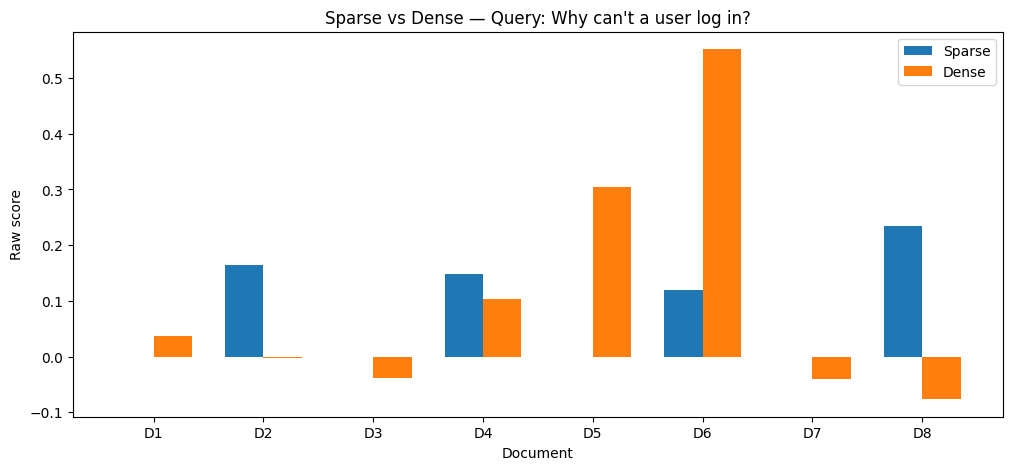

In [26]:
# Compare sparse vs dense score patterns for the same semantic query.
comparison = pd.DataFrame({
    "document": df["id"],
    "sparse_score": sparse_semantic_scores,
    "dense_score": dense_semantic_scores,
})

print("Same query, two completely different relevance signals:")
display(comparison)

# Plot both score families side by side.
x = np.arange(len(df))
width = 0.35

plt.figure(figsize=(12, 5))
plt.bar(x - width / 2, comparison["sparse_score"], width, label="Sparse")
plt.bar(x + width / 2, comparison["dense_score"], width, label="Dense")
plt.xticks(x, df["id"])
plt.xlabel("Document")
plt.ylabel("Raw score")
plt.title("Sparse vs Dense — Query: Why can't a user log in?")
plt.legend()
plt.show()


### Important warning about the previous chart

Do **not** assume sparse score `0.6` and dense score `0.6` mean exactly the same thing.

They come from different scoring systems.

This matters later when we try to combine them.

That is why Hybrid Search needs a **fusion strategy**.


# 12. Visualize Embedding Space in 2D

Real embeddings may have hundreds or thousands of dimensions. Humans cannot directly visualize 384 dimensions.

For learning, we can use **PCA** to project those vectors into 2 dimensions.

### Important

PCA is only a visualization aid here. The actual retrieval still uses the full embedding vectors.


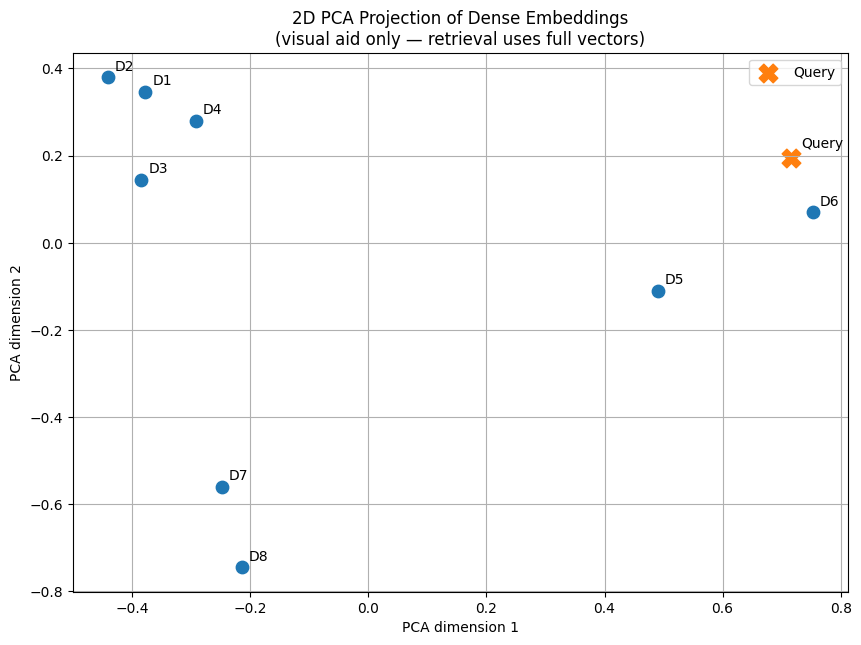

In [27]:
# Import PCA for dimensionality reduction used only in visualization.
from sklearn.decomposition import PCA

# Add the query embedding to the document embeddings.
all_vectors = np.vstack([document_embeddings, login_query_embedding])

# Reduce 384 dimensions down to 2 just for plotting.
pca = PCA(n_components=2)
points_2d = pca.fit_transform(all_vectors)

# Split document points and query point.
doc_points = points_2d[:-1]
query_point = points_2d[-1]

plt.figure(figsize=(10, 7))

# Plot document embeddings.
plt.scatter(doc_points[:, 0], doc_points[:, 1], s=80)

# Label each document.
for i, doc_id in enumerate(df["id"]):
    plt.annotate(doc_id, (doc_points[i, 0], doc_points[i, 1]), xytext=(5, 5), textcoords="offset points")

# Plot the query as a different marker.
plt.scatter(query_point[0], query_point[1], marker="X", s=180, label="Query")
plt.annotate("Query", (query_point[0], query_point[1]), xytext=(8, 8), textcoords="offset points")

plt.title("2D PCA Projection of Dense Embeddings\n(visual aid only — retrieval uses full vectors)")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.legend()
plt.grid(True)
plt.show()


# 13. Why Dense Search Alone Is Not Enough

Dense retrieval is powerful, but enterprise data contains many exact values:

```text
Product codes
Regulation numbers
Article numbers
Error codes
Version numbers
Chemical IDs
Ticket IDs
Names and acronyms
```

Example:

```text
Query: 6ES7513-1AL02-0AB0
```

The exact string matters more than general semantic similarity.

Another example:

```text
Article 33
vs
Article 34
```

The sentences around them can be semantically similar, but legally the article number changes the meaning.

Therefore:

```text
Dense strength:
meaning / synonyms / paraphrases

Dense weakness:
exact identifiers can be under-emphasized
```


In [28]:
# Compare sparse and dense retrieval for an exact product code.
print("### SPARSE RESULT ###")
_, sparse_code_scores = sparse_search_verbose(
    "6ES7513-1AL02-0AB0",
    top_k=4,
    show_all_scores=False,
)

print("\n\n### DENSE RESULT ###")
_, dense_code_scores, _ = dense_search_verbose(
    "6ES7513-1AL02-0AB0",
    top_k=4,
    show_all_scores=False,
)


### SPARSE RESULT ###
SPARSE RETRIEVAL
1) RAW QUERY:
   6ES7513-1AL02-0AB0

2) QUERY VECTOR SHAPE:
   (1, 80)

3) NON-ZERO QUERY FEATURES:
   0ab0               -> 0.5774
   1al02              -> 0.5774
   6es7513            -> 0.5774

5) RANKING ORDER:
   Rank 1: D7 | score=0.5739
   Rank 2: D8 | score=0.0000
   Rank 3: D6 | score=0.0000
   Rank 4: D5 | score=0.0000

6) FINAL TOP-K RESULTS:


,id,type,text,sparse_score
6,D7,product_code,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation component.,0.573945
7,D8,product_semantic,Industrial automation hardware can be selected based on controller capacity and communication requirements.,0.000000
5,D6,support_semantic,Users who cannot sign in should verify credentials and reset their password if necessary.,0.000000
4,D5,error_code,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.000000




### DENSE RESULT ###
DENSE / SEMANTIC RETRIEVAL
1) RAW QUERY:
   6ES7513-1AL02-0AB0

2) QUERY EMBEDDING SHAPE:
   (384,)

3) FIRST 10 QUERY EMBEDDING VALUES:
   [-0.1041  0.0135 -0.0435 -0.0453  0.0278  0.0126  0.035  -0.009   0.0034
 -0.0371]

5) RANKING ORDER:
   Rank 1: D7 | score=0.5402
   Rank 2: D5 | score=0.2719
   Rank 3: D1 | score=0.1211
   Rank 4: D4 | score=0.0931

6) FINAL TOP-K RESULTS:


,id,type,text,dense_score
6,D7,product_code,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation component.,0.540156
4,D5,error_code,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.271899
0,D1,legal_exact,REACH Regulation EC 1907/2006 governs chemical substances.,0.121078
3,D4,product_regulation,RoHS restricts certain hazardous substances in electrical and electronic equipment.,0.093059


# 14. Query Types — A Very Useful Mental Model

Real queries can be grouped loosely into three types.

### Type A — Exact lookup

```text
E401
REACH Article 33
6ES7513-1AL02-0AB0
```

Sparse retrieval often contributes strongly.

### Type B — Semantic question

```text
Why can't users log in?
Which European law controls dangerous chemicals?
```

Dense retrieval often contributes strongly.

### Type C — Mixed enterprise query

```text
What does REACH Article 33 require suppliers to disclose about SVHCs?
```

This contains both exact and semantic information.

Mixed queries are a major reason Hybrid Search is valuable.


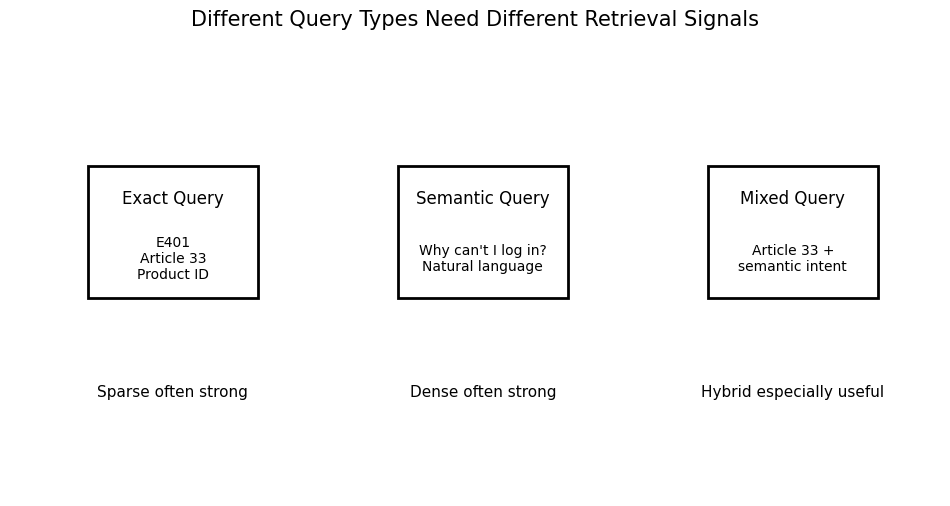

In [29]:
# Build a visual decision-style diagram for query types.
fig, ax = plt.subplots(figsize=(12, 6))
ax.axis("off")
ax.set_xlim(0, 12)
ax.set_ylim(0, 7)

items = [
    ("Exact Query", "E401\nArticle 33\nProduct ID", 1.0),
    ("Semantic Query", "Why can't I log in?\nNatural language", 5.0),
    ("Mixed Query", "Article 33 +\nsemantic intent", 9.0),
]

for title, example, x in items:
    rect = Rectangle((x, 3.0), 2.2, 2.0, fill=False, linewidth=2)
    ax.add_patch(rect)
    ax.text(x + 1.1, 4.5, title, ha="center", va="center", fontsize=12)
    ax.text(x + 1.1, 3.6, example, ha="center", va="center", fontsize=10)

ax.text(2.1, 1.5, "Sparse often strong", ha="center", fontsize=11)
ax.text(6.1, 1.5, "Dense often strong", ha="center", fontsize=11)
ax.text(10.1, 1.5, "Hybrid especially useful", ha="center", fontsize=11)

ax.set_title("Different Query Types Need Different Retrieval Signals", fontsize=15)
plt.show()


# 15. Hybrid Search = Combine the Signals

A basic Hybrid Search pipeline is:

```text
                       Query
                         │
              ┌──────────┴──────────┐
              ▼                     ▼
          Sparse Search         Dense Search
              │                     │
              ▼                     ▼
         Sparse scores          Dense scores
              │                     │
              └──────────┬──────────┘
                         ▼
                      Fusion
                         ↓
                 Combined ranking
```

### Fusion is necessary because

The sparse and dense score ranges are not guaranteed to be directly comparable.

For example:

```text
Sparse scores: 12.5, 7.4, 3.1
Dense scores : 0.91, 0.82, 0.76
```

Simply adding them would let the numeric scale dominate.


# 16. Score Normalization — Explain It Before Using It

One simple approach is **min-max normalization**.

It maps a score list into the range:

```text
0 to 1
```

Formula:

$$
\text{normalized}(x) = \frac{x - \min}{\max - \min}
$$
Example:

```text
Original:  10, 20, 30
Normalized: 0, 0.5, 1
```

The highest score becomes `1`, the lowest becomes `0`, and the others fall in between.


In [30]:
def min_max_normalize_verbose(values, label="scores"):
    """Normalize numbers into 0..1 while printing each calculation."""

    # Convert values to a numeric array.
    values = np.asarray(values, dtype=float)

    # Find minimum and maximum.
    minimum = values.min()
    maximum = values.max()

    print(f"Original {label} :", np.round(values, 4))
    print("Minimum          :", round(float(minimum), 4))
    print("Maximum          :", round(float(maximum), 4))

    # Protect against division by zero when all values are identical.
    if maximum == minimum:
        normalized = np.zeros_like(values)
    else:
        normalized = (values - minimum) / (maximum - minimum)

    print("Normalized       :", np.round(normalized, 4))

    return normalized


# Use easy numbers first.
example_scores = [10, 20, 30]
normalized_example = min_max_normalize_verbose(example_scores, "example scores")


Original example scores : [10. 20. 30.]
Minimum          : 10.0
Maximum          : 30.0
Normalized       : [0.  0.5 1. ]


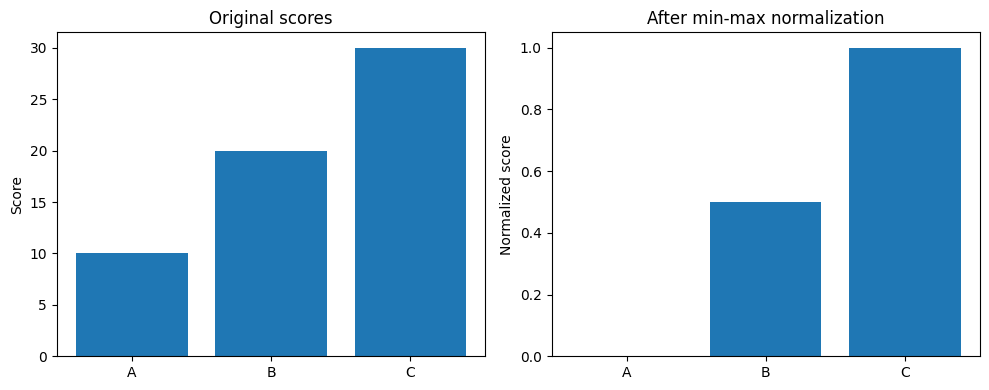

In [31]:
# Visualize before and after normalization.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(["A", "B", "C"], example_scores)
axes[0].set_title("Original scores")
axes[0].set_ylabel("Score")

axes[1].bar(["A", "B", "C"], normalized_example)
axes[1].set_title("After min-max normalization")
axes[1].set_ylabel("Normalized score")

plt.tight_layout()
plt.show()


# 17. Weighted Fusion

After normalization, a simple educational Hybrid score can be:

$$
\text{HybridScore} = \alpha \cdot \text{Dense} + (1-\alpha) \cdot \text{Sparse}
$$

### What is `alpha`?

`alpha` controls how much weight dense retrieval receives.

```text
alpha = 0.0 → sparse only
alpha = 0.2 → sparse-heavy
alpha = 0.5 → balanced
alpha = 0.8 → dense-heavy
alpha = 1.0 → dense only
```

This is **not automatically the best production fusion method**. We use it because it makes the idea visible. Later we will study methods such as **Reciprocal Rank Fusion (RRF)**.


In [32]:
def min_max_normalize(values):
    """Simple reusable non-verbose normalizer."""
    values = np.asarray(values, dtype=float)
    minimum = values.min()
    maximum = values.max()
    if maximum == minimum:
        return np.zeros_like(values)
    return (values - minimum) / (maximum - minimum)


def hybrid_search_verbose(query, top_k=5, alpha=0.5):
    """Run sparse + dense retrieval and print every major fusion step."""

    print("=" * 110)
    print("HYBRID SEARCH")
    print("=" * 110)
    print("QUERY:", query)
    print("alpha (dense weight):", alpha)
    print("sparse weight       :", 1 - alpha)

    # ---------- Sparse branch ----------
    sparse_query_vector = tfidf_vectorizer.transform([query])
    sparse_raw = cosine_similarity(
        sparse_query_vector,
        tfidf_document_matrix,
    ).flatten()

    # ---------- Dense branch ----------
    dense_query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True,
    )[0]
    dense_raw = document_embeddings @ dense_query_embedding

    # ---------- Normalize ----------
    sparse_norm = min_max_normalize(sparse_raw)
    dense_norm = min_max_normalize(dense_raw)

    # ---------- Weighted fusion ----------
    hybrid_score = (
        (1 - alpha) * sparse_norm
        + alpha * dense_norm
    )

    # Show calculation per document.
    print("\nPER-DOCUMENT FUSION CALCULATION")
    print("-" * 110)
    for i, row in df.iterrows():
        print(
            f"{row['id']}: "
            f"sparse_raw={sparse_raw[i]:.4f}, "
            f"dense_raw={dense_raw[i]:.4f}, "
            f"sparse_norm={sparse_norm[i]:.4f}, "
            f"dense_norm={dense_norm[i]:.4f}, "
            f"hybrid={hybrid_score[i]:.4f}"
        )

    # Rank by combined score.
    ranked_indices = np.argsort(hybrid_score)[::-1]

    print("\nFINAL RANKING")
    print("-" * 110)
    for rank, idx in enumerate(ranked_indices[:top_k], start=1):
        print(f"Rank {rank}: {df.iloc[idx]['id']} | hybrid={hybrid_score[idx]:.4f}")

    # Build result table.
    results = df.iloc[ranked_indices[:top_k]].copy()
    results["sparse_raw"] = sparse_raw[ranked_indices[:top_k]]
    results["dense_raw"] = dense_raw[ranked_indices[:top_k]]
    results["sparse_norm"] = sparse_norm[ranked_indices[:top_k]]
    results["dense_norm"] = dense_norm[ranked_indices[:top_k]]
    results["hybrid_score"] = hybrid_score[ranked_indices[:top_k]]

    print("\nTOP-K TABLE")
    display(results[[
        "id",
        "type",
        "text",
        "sparse_norm",
        "dense_norm",
        "hybrid_score",
    ]])

    # Return both table and full score arrays for visualization.
    return results, sparse_norm, dense_norm, hybrid_score


## 17.1 Mixed Query — Ideal Hybrid Search Example

```text
What does REACH Article 33 require suppliers to disclose about SVHCs?
```

This query contains:

```text
Exact lexical clues:
REACH
Article 33
SVHC

Semantic intent:
what must suppliers disclose?
```


In [33]:
hybrid_results, hybrid_sparse, hybrid_dense, hybrid_scores = hybrid_search_verbose(
    "What does REACH Article 33 require suppliers to disclose about SVHCs?",
    top_k=5,
    alpha=0.5,
)


HYBRID SEARCH
QUERY: What does REACH Article 33 require suppliers to disclose about SVHCs?
alpha (dense weight): 0.5
sparse weight       : 0.5

PER-DOCUMENT FUSION CALCULATION
--------------------------------------------------------------------------------------------------------------
D1: sparse_raw=0.1018, dense_raw=0.2689, sparse_norm=0.1578, dense_norm=0.3259, hybrid=0.2418
D2: sparse_raw=0.0000, dense_raw=0.2290, sparse_norm=0.0000, dense_norm=0.2807, hybrid=0.1403
D3: sparse_raw=0.6451, dense_raw=0.8628, sparse_norm=1.0000, dense_norm=1.0000, hybrid=1.0000
D4: sparse_raw=0.0000, dense_raw=0.3137, sparse_norm=0.0000, dense_norm=0.3767, hybrid=0.1884
D5: sparse_raw=0.0000, dense_raw=0.0482, sparse_norm=0.0000, dense_norm=0.0755, hybrid=0.0377
D6: sparse_raw=0.0000, dense_raw=-0.0183, sparse_norm=0.0000, dense_norm=0.0000, hybrid=0.0000
D7: sparse_raw=0.0000, dense_raw=0.2013, sparse_norm=0.0000, dense_norm=0.2492, hybrid=0.1246
D8: sparse_raw=0.0000, dense_raw=0.1461, sparse_norm=0

,id,type,text,sparse_norm,dense_norm,hybrid_score
2,D3,legal_exact,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, also called SVHCs.",1.000000,1.000000,1.000000
0,D1,legal_exact,REACH Regulation EC 1907/2006 governs chemical substances.,0.157779,0.325899,0.241839
3,D4,product_regulation,RoHS restricts certain hazardous substances in electrical and electronic equipment.,0.000000,0.376749,0.188374
1,D2,legal_semantic,European rules control hazardous substances used in products.,0.000000,0.280652,0.140326
6,D7,product_code,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation component.,0.000000,0.249185,0.124593


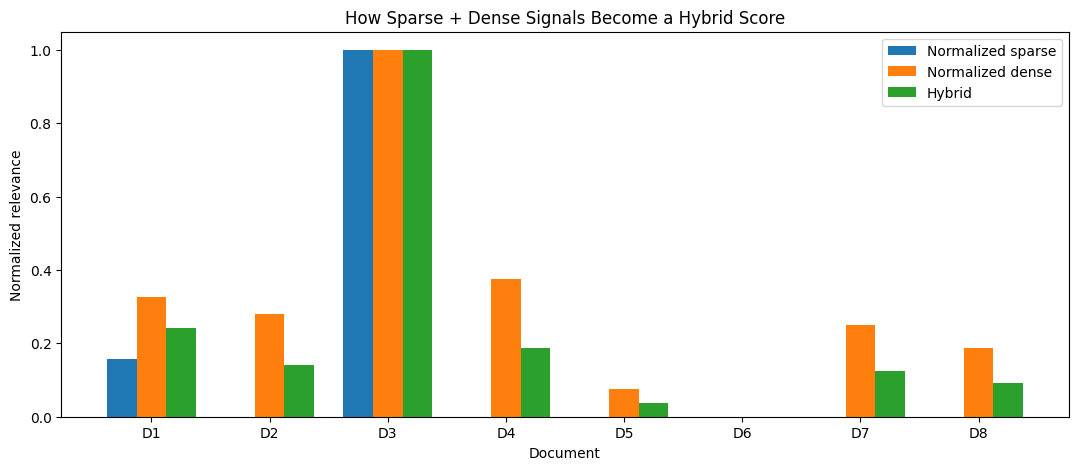

In [34]:
# Visualize the three signals for every document.
x = np.arange(len(df))
width = 0.25

plt.figure(figsize=(13, 5))
plt.bar(x - width, hybrid_sparse, width, label="Normalized sparse")
plt.bar(x, hybrid_dense, width, label="Normalized dense")
plt.bar(x + width, hybrid_scores, width, label="Hybrid")

plt.xticks(x, df["id"])
plt.xlabel("Document")
plt.ylabel("Normalized relevance")
plt.title("How Sparse + Dense Signals Become a Hybrid Score")
plt.legend()
plt.show()


# 18. Alpha Experiment — See How Ranking Changes

The same query can behave differently depending on how much weight each retrieval signal receives.

We will compare:

```text
0.2 → sparse-heavy
0.5 → balanced
0.8 → dense-heavy
```


In [35]:
query = "REACH 1907/2006 hazardous chemical requirements"

alpha_rows = []

for alpha in [0.2, 0.5, 0.8]:
    print("\n" + "#" * 100)
    print("ALPHA =", alpha)

    results, _, _, _ = hybrid_search_verbose(
        query,
        top_k=3,
        alpha=alpha,
    )

    # Save a compact summary for later comparison.
    alpha_rows.append({
        "alpha": alpha,
        "rank_1": results.iloc[0]["id"],
        "rank_2": results.iloc[1]["id"],
        "rank_3": results.iloc[2]["id"],
    })

print("\nSUMMARY OF TOP-3 RANKINGS")
display(pd.DataFrame(alpha_rows))



####################################################################################################
ALPHA = 0.2
HYBRID SEARCH
QUERY: REACH 1907/2006 hazardous chemical requirements
alpha (dense weight): 0.2
sparse weight       : 0.8

PER-DOCUMENT FUSION CALCULATION
--------------------------------------------------------------------------------------------------------------
D1: sparse_raw=0.5975, dense_raw=0.6623, sparse_norm=1.0000, dense_norm=1.0000, hybrid=1.0000
D2: sparse_raw=0.1174, dense_raw=0.5214, sparse_norm=0.1964, dense_norm=0.8030, hybrid=0.3177
D3: sparse_raw=0.0753, dense_raw=0.3858, sparse_norm=0.1260, dense_norm=0.6136, hybrid=0.2235
D4: sparse_raw=0.1058, dense_raw=0.4180, sparse_norm=0.1771, dense_norm=0.6586, hybrid=0.2734
D5: sparse_raw=0.0000, dense_raw=0.0967, sparse_norm=0.0000, dense_norm=0.2095, hybrid=0.0419
D6: sparse_raw=0.0000, dense_raw=-0.0532, sparse_norm=0.0000, dense_norm=0.0000, hybrid=0.0000
D7: sparse_raw=0.0000, dense_raw=0.2039, sparse_norm=0.0

,id,type,text,sparse_norm,dense_norm,hybrid_score
0,D1,legal_exact,REACH Regulation EC 1907/2006 governs chemical substances.,1.000000,1.000000,1.000000
1,D2,legal_semantic,European rules control hazardous substances used in products.,0.196418,0.803004,0.317735
3,D4,product_regulation,RoHS restricts certain hazardous substances in electrical and electronic equipment.,0.177118,0.658599,0.273414



####################################################################################################
ALPHA = 0.5
HYBRID SEARCH
QUERY: REACH 1907/2006 hazardous chemical requirements
alpha (dense weight): 0.5
sparse weight       : 0.5

PER-DOCUMENT FUSION CALCULATION
--------------------------------------------------------------------------------------------------------------
D1: sparse_raw=0.5975, dense_raw=0.6623, sparse_norm=1.0000, dense_norm=1.0000, hybrid=1.0000
D2: sparse_raw=0.1174, dense_raw=0.5214, sparse_norm=0.1964, dense_norm=0.8030, hybrid=0.4997
D3: sparse_raw=0.0753, dense_raw=0.3858, sparse_norm=0.1260, dense_norm=0.6136, hybrid=0.3698
D4: sparse_raw=0.1058, dense_raw=0.4180, sparse_norm=0.1771, dense_norm=0.6586, hybrid=0.4179
D5: sparse_raw=0.0000, dense_raw=0.0967, sparse_norm=0.0000, dense_norm=0.2095, hybrid=0.1048
D6: sparse_raw=0.0000, dense_raw=-0.0532, sparse_norm=0.0000, dense_norm=0.0000, hybrid=0.0000
D7: sparse_raw=0.0000, dense_raw=0.2039, sparse_norm=0.0

,id,type,text,sparse_norm,dense_norm,hybrid_score
0,D1,legal_exact,REACH Regulation EC 1907/2006 governs chemical substances.,1.000000,1.000000,1.000000
1,D2,legal_semantic,European rules control hazardous substances used in products.,0.196418,0.803004,0.499711
3,D4,product_regulation,RoHS restricts certain hazardous substances in electrical and electronic equipment.,0.177118,0.658599,0.417859



####################################################################################################
ALPHA = 0.8
HYBRID SEARCH
QUERY: REACH 1907/2006 hazardous chemical requirements
alpha (dense weight): 0.8
sparse weight       : 0.19999999999999996

PER-DOCUMENT FUSION CALCULATION
--------------------------------------------------------------------------------------------------------------
D1: sparse_raw=0.5975, dense_raw=0.6623, sparse_norm=1.0000, dense_norm=1.0000, hybrid=1.0000
D2: sparse_raw=0.1174, dense_raw=0.5214, sparse_norm=0.1964, dense_norm=0.8030, hybrid=0.6817
D3: sparse_raw=0.0753, dense_raw=0.3858, sparse_norm=0.1260, dense_norm=0.6136, hybrid=0.5161
D4: sparse_raw=0.1058, dense_raw=0.4180, sparse_norm=0.1771, dense_norm=0.6586, hybrid=0.5623
D5: sparse_raw=0.0000, dense_raw=0.0967, sparse_norm=0.0000, dense_norm=0.2095, hybrid=0.1676
D6: sparse_raw=0.0000, dense_raw=-0.0532, sparse_norm=0.0000, dense_norm=0.0000, hybrid=0.0000
D7: sparse_raw=0.0000, dense_raw=0.2039,

,id,type,text,sparse_norm,dense_norm,hybrid_score
0,D1,legal_exact,REACH Regulation EC 1907/2006 governs chemical substances.,1.000000,1.000000,1.000000
1,D2,legal_semantic,European rules control hazardous substances used in products.,0.196418,0.803004,0.681687
3,D4,product_regulation,RoHS restricts certain hazardous substances in electrical and electronic equipment.,0.177118,0.658599,0.562303



SUMMARY OF TOP-3 RANKINGS


,alpha,rank_1,rank_2,rank_3
0,0.2,D1,D2,D4
1,0.5,D1,D2,D4
2,0.8,D1,D2,D4


## What should you learn from alpha?

Do **not** memorize a fixed value such as `0.5`.

Different datasets and query types may need different behavior.

Later we will learn:

- evaluation-driven weight tuning
- dynamic query weighting
- Reciprocal Rank Fusion

For now, the important lesson is:

> Hybrid Search needs a rule for combining multiple relevance signals.


# 19. Fusion vs Reranking — Do Not Confuse Them

These are separate stages.

## Fusion

Combines multiple retrieval result lists or scores.

```text
Sparse Results ──┐
                 ├── Fusion → Combined candidates
Dense Results  ──┘
```

## Reranking

Uses a stronger and usually more expensive model to judge a **small candidate set** more carefully.

```text
Hybrid Top-20
     ↓
Reranker
     ↓
Top-5
```

A reranker can be:

- cross-encoder model
- specialized reranking model
- LLM-based relevance judge

We will study reranking deeply in a later chapter.


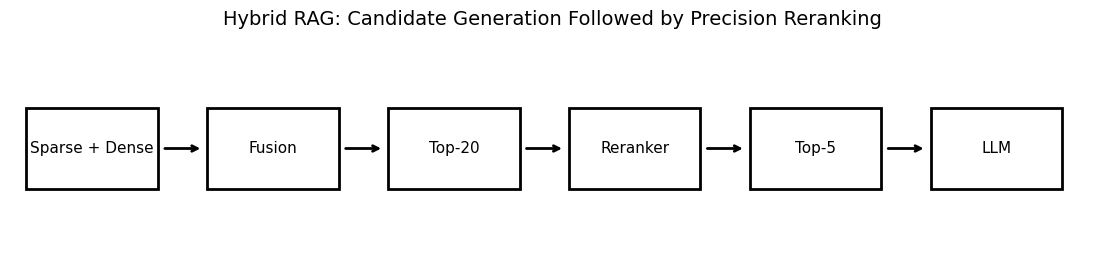

In [36]:
# Draw Retrieval → Fusion → Reranking → LLM.
draw_flow_diagram(
    ["Sparse + Dense", "Fusion", "Top-20", "Reranker", "Top-5", "LLM"],
    "Hybrid RAG: Candidate Generation Followed by Precision Reranking",
)


# 20. High Recall First, High Precision Later

A useful production mental model is:

```text
Initial retrieval
      ↓
Try not to miss relevant documents
      ↓
High recall candidate set
      ↓
Reranker
      ↓
Remove weak candidates
      ↓
High precision final context
```

### Recall intuition

> Of all truly relevant documents, how many did retrieval successfully find?

### Precision intuition

> Of the documents we retrieved, how many are actually relevant?

A common design pattern is:

```text
Retriever → favor recall
Reranker  → improve precision
```

This is not an absolute law, but it is a very useful architecture principle.


# 21. Why Retrieval Quality Can Limit the Entire RAG System

Suppose the correct answer lives in `Document 837`.

But retrieval returns:

```text
D4
D10
D49
D82
D101
```

The LLM never receives `D837`.

Even a powerful LLM cannot reliably use evidence it was never given.

A useful mental model is:

$$
\text{AnswerQuality} \approx \text{RetrievalQuality} \times \text{GenerationQuality}
$$

This is **not a formal equation**. It simply reminds us that bad evidence can ruin a good generator.


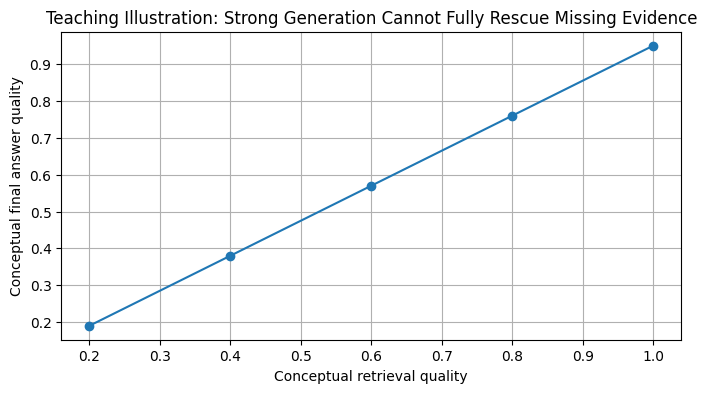

In [37]:
# Visualize a conceptual quality bottleneck.
retrieval_quality = np.array([0.2, 0.4, 0.6, 0.8, 1.0])
generation_quality = 0.95
conceptual_answer_quality = retrieval_quality * generation_quality

plt.figure(figsize=(8, 4))
plt.plot(retrieval_quality, conceptual_answer_quality, marker="o")
plt.xlabel("Conceptual retrieval quality")
plt.ylabel("Conceptual final answer quality")
plt.title("Teaching Illustration: Strong Generation Cannot Fully Rescue Missing Evidence")
plt.grid(True)
plt.show()


# 22. Search vs RAG — Another Important Distinction

### Search system

```text
Query
 ↓
Retriever
 ↓
Documents
```

It returns documents.

### RAG system

```text
Query
 ↓
Retriever
 ↓
Documents
 ↓
LLM
 ↓
Generated answer
```

Therefore:

> **Hybrid Search can exist without an LLM.**

An ecommerce product search engine could use sparse + dense retrieval without any generation step.


# 23. Hybrid Search Does NOT Fix Everything

Hybrid Search is powerful, but it cannot automatically repair problems earlier or later in the pipeline.

It does not magically fix:

```text
Bad OCR
Missing documents
Poor PDF parsing
Incorrect chunks
Corrupted identifiers
Wrong metadata filters
Weak embedding model
Bad reranker
Hallucinating LLM
```

Think of RAG as a chain:

```text
Data
 ↓
Parsing
 ↓
Chunking
 ↓
Indexing
 ↓
Retrieval
 ↓
Fusion
 ↓
Reranking
 ↓
Context
 ↓
Generation
```

A failure at any stage can reduce final quality.


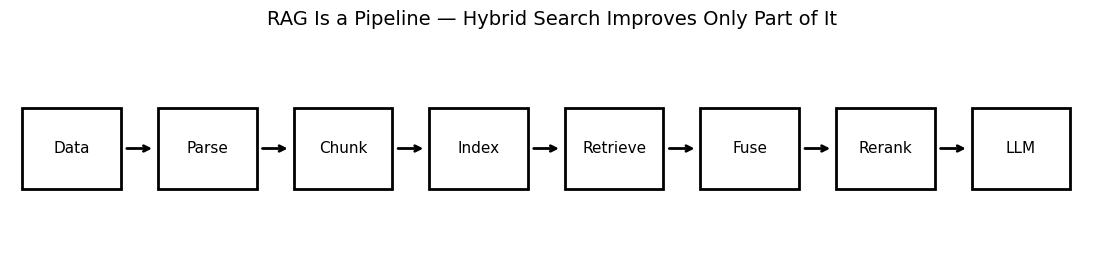

In [38]:
# Draw the complete stage-by-stage chain.
draw_flow_diagram(
    ["Data", "Parse", "Chunk", "Index", "Retrieve", "Fuse", "Rerank", "LLM"],
    "RAG Is a Pipeline — Hybrid Search Improves Only Part of It",
)


# 24. Production Debugging Framework

When the answer is wrong, debug in order instead of immediately changing the LLM.

```text
1. Does the correct source exist?
2. Was it parsed correctly?
3. Is the correct information inside a searchable chunk?
4. Did sparse retrieval find it?
5. Did dense retrieval find it?
6. Did fusion keep it?
7. Did the reranker remove it?
8. Did the final context include it?
9. Did the LLM misunderstand it?
```

### This separation is extremely important

If the correct chunk is missing before the LLM stage, prompt engineering may not solve the root cause.


In [39]:
def debug_retrieval(query, top_k=5, alpha=0.5):
    """Convenience function for side-by-side retrieval debugging."""

    print("#" * 110)
    print("DEBUG QUERY:", query)
    print("#" * 110)

    print("\nSTEP A — SPARSE")
    sparse_results, _ = sparse_search_verbose(
        query,
        top_k=top_k,
        show_all_scores=False,
    )

    print("\nSTEP B — DENSE")
    dense_results, _, _ = dense_search_verbose(
        query,
        top_k=top_k,
        show_all_scores=False,
    )

    print("\nSTEP C — HYBRID")
    hybrid_results, _, _, _ = hybrid_search_verbose(
        query,
        top_k=top_k,
        alpha=alpha,
    )

    print("\nCOMPACT COMPARISON")
    comparison = pd.DataFrame({
        "sparse_rank": sparse_results["id"].tolist(),
        "dense_rank": dense_results["id"].tolist(),
        "hybrid_rank": hybrid_results["id"].tolist(),
    })
    display(comparison)

    return comparison


## 24.1 Debug Three Different Query Styles

Observe how the retrievers behave differently.


In [40]:
# Exact lookup.
debug_retrieval("E401", top_k=4, alpha=0.5)


##############################################################################################################
DEBUG QUERY: E401
##############################################################################################################

STEP A — SPARSE
SPARSE RETRIEVAL
1) RAW QUERY:
   E401

2) QUERY VECTOR SHAPE:
   (1, 80)

3) NON-ZERO QUERY FEATURES:
   e401               -> 1.0000

5) RANKING ORDER:
   Rank 1: D5 | score=0.2839
   Rank 2: D8 | score=0.0000
   Rank 3: D7 | score=0.0000
   Rank 4: D6 | score=0.0000

6) FINAL TOP-K RESULTS:


,id,type,text,sparse_score
4,D5,error_code,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.283927
7,D8,product_semantic,Industrial automation hardware can be selected based on controller capacity and communication requirements.,0.000000
6,D7,product_code,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation component.,0.000000
5,D6,support_semantic,Users who cannot sign in should verify credentials and reset their password if necessary.,0.000000



STEP B — DENSE
DENSE / SEMANTIC RETRIEVAL
1) RAW QUERY:
   E401

2) QUERY EMBEDDING SHAPE:
   (384,)

3) FIRST 10 QUERY EMBEDDING VALUES:
   [-0.0662  0.0729  0.0559 -0.0016 -0.0142 -0.0489  0.0715  0.0996 -0.044
  0.0363]

5) RANKING ORDER:
   Rank 1: D5 | score=0.5415
   Rank 2: D7 | score=0.2747
   Rank 3: D1 | score=0.1492
   Rank 4: D8 | score=0.1436

6) FINAL TOP-K RESULTS:


,id,type,text,dense_score
4,D5,error_code,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.541511
6,D7,product_code,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation component.,0.274679
0,D1,legal_exact,REACH Regulation EC 1907/2006 governs chemical substances.,0.149159
7,D8,product_semantic,Industrial automation hardware can be selected based on controller capacity and communication requirements.,0.143601



STEP C — HYBRID
HYBRID SEARCH
QUERY: E401
alpha (dense weight): 0.5
sparse weight       : 0.5

PER-DOCUMENT FUSION CALCULATION
--------------------------------------------------------------------------------------------------------------
D1: sparse_raw=0.0000, dense_raw=0.1492, sparse_norm=0.0000, dense_norm=0.2864, hybrid=0.1432
D2: sparse_raw=0.0000, dense_raw=0.1004, sparse_norm=0.0000, dense_norm=0.1977, hybrid=0.0988
D3: sparse_raw=0.0000, dense_raw=0.1125, sparse_norm=0.0000, dense_norm=0.2198, hybrid=0.1099
D4: sparse_raw=0.0000, dense_raw=0.0871, sparse_norm=0.0000, dense_norm=0.1735, hybrid=0.0868
D5: sparse_raw=0.2839, dense_raw=0.5415, sparse_norm=1.0000, dense_norm=1.0000, hybrid=1.0000
D6: sparse_raw=0.0000, dense_raw=-0.0083, sparse_norm=0.0000, dense_norm=0.0000, hybrid=0.0000
D7: sparse_raw=0.0000, dense_raw=0.2747, sparse_norm=0.0000, dense_norm=0.5147, hybrid=0.2574
D8: sparse_raw=0.0000, dense_raw=0.1436, sparse_norm=0.0000, dense_norm=0.2763, hybrid=0.1382

FINAL R

,id,type,text,sparse_norm,dense_norm,hybrid_score
4,D5,error_code,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,1.0,1.000000,1.000000
6,D7,product_code,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation component.,0.0,0.514711,0.257356
0,D1,legal_exact,REACH Regulation EC 1907/2006 governs chemical substances.,0.0,0.286428,0.143214
7,D8,product_semantic,Industrial automation hardware can be selected based on controller capacity and communication requirements.,0.0,0.276319,0.138160



COMPACT COMPARISON


,sparse_rank,dense_rank,hybrid_rank
0,D5,D5,D5
1,D8,D7,D7
2,D7,D1,D1
3,D6,D8,D8


,sparse_rank,dense_rank,hybrid_rank
0,D5,D5,D5
1,D8,D7,D7
2,D7,D1,D1
3,D6,D8,D8


In [41]:
# Semantic natural-language question.
debug_retrieval("Why can't users sign in?", top_k=4, alpha=0.5)


##############################################################################################################
DEBUG QUERY: Why can't users sign in?
##############################################################################################################

STEP A — SPARSE
SPARSE RETRIEVAL
1) RAW QUERY:
   Why can't users sign in?

2) QUERY VECTOR SHAPE:
   (1, 80)

3) NON-ZERO QUERY FEATURES:
   can                -> 0.5328
   in                 -> 0.3853
   sign               -> 0.5328
   users              -> 0.5328

5) RANKING ORDER:
   Rank 1: D6 | score=0.3765
   Rank 2: D8 | score=0.1543
   Rank 3: D2 | score=0.1082
   Rank 4: D4 | score=0.0976

6) FINAL TOP-K RESULTS:


,id,type,text,sparse_score
5,D6,support_semantic,Users who cannot sign in should verify credentials and reset their password if necessary.,0.376473
7,D8,product_semantic,Industrial automation hardware can be selected based on controller capacity and communication requirements.,0.154264
1,D2,legal_semantic,European rules control hazardous substances used in products.,0.108238
3,D4,product_regulation,RoHS restricts certain hazardous substances in electrical and electronic equipment.,0.097602



STEP B — DENSE
DENSE / SEMANTIC RETRIEVAL
1) RAW QUERY:
   Why can't users sign in?

2) QUERY EMBEDDING SHAPE:
   (384,)

3) FIRST 10 QUERY EMBEDDING VALUES:
   [ 0.0574 -0.0324 -0.0361 -0.0482 -0.0254 -0.0285  0.0227  0.004   0.0446
 -0.0272]

5) RANKING ORDER:
   Rank 1: D6 | score=0.6121
   Rank 2: D5 | score=0.3175
   Rank 3: D4 | score=0.0847
   Rank 4: D1 | score=0.0236

6) FINAL TOP-K RESULTS:


,id,type,text,dense_score
5,D6,support_semantic,Users who cannot sign in should verify credentials and reset their password if necessary.,0.612127
4,D5,error_code,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.317490
3,D4,product_regulation,RoHS restricts certain hazardous substances in electrical and electronic equipment.,0.084732
0,D1,legal_exact,REACH Regulation EC 1907/2006 governs chemical substances.,0.023555



STEP C — HYBRID
HYBRID SEARCH
QUERY: Why can't users sign in?
alpha (dense weight): 0.5
sparse weight       : 0.5

PER-DOCUMENT FUSION CALCULATION
--------------------------------------------------------------------------------------------------------------
D1: sparse_raw=0.0000, dense_raw=0.0236, sparse_norm=0.0000, dense_norm=0.1650, hybrid=0.0825
D2: sparse_raw=0.1082, dense_raw=-0.0262, sparse_norm=0.2875, dense_norm=0.0943, hybrid=0.1909
D3: sparse_raw=0.0000, dense_raw=-0.0544, sparse_norm=0.0000, dense_norm=0.0543, hybrid=0.0272
D4: sparse_raw=0.0976, dense_raw=0.0847, sparse_norm=0.2593, dense_norm=0.2518, hybrid=0.2555
D5: sparse_raw=0.0000, dense_raw=0.3175, sparse_norm=0.0000, dense_norm=0.5820, hybrid=0.2910
D6: sparse_raw=0.3765, dense_raw=0.6121, sparse_norm=1.0000, dense_norm=1.0000, hybrid=1.0000
D7: sparse_raw=0.0000, dense_raw=-0.0657, sparse_norm=0.0000, dense_norm=0.0383, hybrid=0.0192
D8: sparse_raw=0.1543, dense_raw=-0.0927, sparse_norm=0.4098, dense_norm=0.0000,

,id,type,text,sparse_norm,dense_norm,hybrid_score
5,D6,support_semantic,Users who cannot sign in should verify credentials and reset their password if necessary.,1.000000,1.000000,1.000000
4,D5,error_code,Error code E401 indicates an authentication failure caused by invalid or expired credentials.,0.000000,0.581990,0.290995
3,D4,product_regulation,RoHS restricts certain hazardous substances in electrical and electronic equipment.,0.259255,0.251772,0.255513
7,D8,product_semantic,Industrial automation hardware can be selected based on controller capacity and communication requirements.,0.409760,0.000000,0.204880



COMPACT COMPARISON


,sparse_rank,dense_rank,hybrid_rank
0,D6,D6,D6
1,D8,D5,D5
2,D2,D4,D4
3,D4,D1,D8


,sparse_rank,dense_rank,hybrid_rank
0,D6,D6,D6
1,D8,D5,D5
2,D2,D4,D4
3,D4,D1,D8


In [42]:
# Mixed exact + semantic query.
debug_retrieval(
    "What does REACH Article 33 require suppliers to communicate?",
    top_k=4,
    alpha=0.5,
)


##############################################################################################################
DEBUG QUERY: What does REACH Article 33 require suppliers to communicate?
##############################################################################################################

STEP A — SPARSE
SPARSE RETRIEVAL
1) RAW QUERY:
   What does REACH Article 33 require suppliers to communicate?

2) QUERY VECTOR SHAPE:
   (1, 80)

3) NON-ZERO QUERY FEATURES:
   33                 -> 0.4188
   article            -> 0.4188
   communicate        -> 0.4188
   reach              -> 0.3510
   suppliers          -> 0.4188
   to                 -> 0.4188

5) RANKING ORDER:
   Rank 1: D3 | score=0.5951
   Rank 2: D1 | score=0.1104
   Rank 3: D8 | score=0.0000
   Rank 4: D7 | score=0.0000

6) FINAL TOP-K RESULTS:


,id,type,text,sparse_score
2,D3,legal_exact,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, also called SVHCs.",0.595052
0,D1,legal_exact,REACH Regulation EC 1907/2006 governs chemical substances.,0.110351
7,D8,product_semantic,Industrial automation hardware can be selected based on controller capacity and communication requirements.,0.000000
6,D7,product_code,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation component.,0.000000



STEP B — DENSE
DENSE / SEMANTIC RETRIEVAL
1) RAW QUERY:
   What does REACH Article 33 require suppliers to communicate?

2) QUERY EMBEDDING SHAPE:
   (384,)

3) FIRST 10 QUERY EMBEDDING VALUES:
   [-0.0188  0.0235 -0.0032 -0.0531 -0.0275  0.0277 -0.06   -0.0201 -0.0253
 -0.0529]

5) RANKING ORDER:
   Rank 1: D3 | score=0.6959
   Rank 2: D1 | score=0.2871
   Rank 3: D4 | score=0.2061
   Rank 4: D7 | score=0.1989

6) FINAL TOP-K RESULTS:


,id,type,text,dense_score
2,D3,legal_exact,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, also called SVHCs.",0.695880
0,D1,legal_exact,REACH Regulation EC 1907/2006 governs chemical substances.,0.287051
3,D4,product_regulation,RoHS restricts certain hazardous substances in electrical and electronic equipment.,0.206150
6,D7,product_code,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation component.,0.198865



STEP C — HYBRID
HYBRID SEARCH
QUERY: What does REACH Article 33 require suppliers to communicate?
alpha (dense weight): 0.5
sparse weight       : 0.5

PER-DOCUMENT FUSION CALCULATION
--------------------------------------------------------------------------------------------------------------
D1: sparse_raw=0.1104, dense_raw=0.2871, sparse_norm=0.1854, dense_norm=0.3923, hybrid=0.2889
D2: sparse_raw=0.0000, dense_raw=0.1975, sparse_norm=0.0000, dense_norm=0.2592, hybrid=0.1296
D3: sparse_raw=0.5951, dense_raw=0.6959, sparse_norm=1.0000, dense_norm=1.0000, hybrid=1.0000
D4: sparse_raw=0.0000, dense_raw=0.2061, sparse_norm=0.0000, dense_norm=0.2720, hybrid=0.1360
D5: sparse_raw=0.0000, dense_raw=0.0552, sparse_norm=0.0000, dense_norm=0.0476, hybrid=0.0238
D6: sparse_raw=0.0000, dense_raw=0.0232, sparse_norm=0.0000, dense_norm=0.0000, hybrid=0.0000
D7: sparse_raw=0.0000, dense_raw=0.1989, sparse_norm=0.0000, dense_norm=0.2612, hybrid=0.1306
D8: sparse_raw=0.0000, dense_raw=0.1809, sparse

,id,type,text,sparse_norm,dense_norm,hybrid_score
2,D3,legal_exact,"REACH Article 33 requires suppliers to communicate information about substances of very high concern, also called SVHCs.",1.000000,1.000000,1.000000
0,D1,legal_exact,REACH Regulation EC 1907/2006 governs chemical substances.,0.185448,0.392263,0.288855
3,D4,product_regulation,RoHS restricts certain hazardous substances in electrical and electronic equipment.,0.000000,0.272000,0.136000
6,D7,product_code,Siemens product 6ES7513-1AL02-0AB0 is an industrial automation component.,0.000000,0.261171,0.130585



COMPACT COMPARISON


,sparse_rank,dense_rank,hybrid_rank
0,D3,D3,D3
1,D1,D1,D1
2,D8,D4,D4
3,D7,D7,D7


,sparse_rank,dense_rank,hybrid_rank
0,D3,D3,D3
1,D1,D1,D1
2,D8,D4,D4
3,D7,D7,D7


# 25. A Simple End-to-End Hybrid RAG Pseudocode

Now that every stage has been introduced, the full logic becomes easier to understand.

```python
query = user_question

# Candidate retrieval
sparse_results = sparse_search(query, top_k=20)
dense_results = dense_search(query, top_k=20)

# Combine evidence
hybrid_candidates = fuse(sparse_results, dense_results)

# Expensive relevance refinement
reranked = rerank(query, hybrid_candidates)

# Keep a small amount of evidence
context = reranked[:5]

# Final generation
answer = llm(question=query, context=context)
```

### The most important sequence

```text
Retrieve
   ↓
Fuse
   ↓
Rerank
   ↓
Build context
   ↓
Generate
```


# 26. When Should You Use Hybrid Search?

Hybrid Search becomes especially attractive when your data contains both semantic text and exact entities.

Strong use cases include:

```text
Regulatory / legal search
Technical support
Machine manuals
Product catalogs
Cybersecurity
Scientific literature
Medical search
Code/documentation search
Enterprise knowledge bases
```

Why?

Because these domains commonly contain:

```text
Natural language
+
IDs
+
acronyms
+
versions
+
rare terminology
+
codes
```


## When might dense search alone be enough?

A small FAQ dataset where users mostly ask natural-language paraphrases.

Example:

```text
How do I reset my password?
I forgot my password.
How can I recover my account?
```

Dense retrieval may already perform very well.

## When might lexical or exact lookup be enough?

If users mostly search exact identifiers:

```text
Ticket ID
Invoice ID
SKU
Fault code
```

Adding embeddings may add little value.

### Engineering principle

> Add Hybrid Search because evaluation shows it solves a retrieval problem — not simply because it sounds more advanced.


# 27. Regulatory Example — Why Hybrid Is a Natural Fit

Regulatory text often contains:

```text
Regulation IDs
Article numbers
Chemical names
CAS numbers
Country names
Acronyms
Legal language
Semantic obligations
```

Example query:

```text
Does REACH Article 33 require suppliers to communicate SVHC information?
```

Sparse evidence:

```text
REACH
Article 33
SVHC
```

Dense evidence:

```text
require suppliers to communicate
≈
disclosure / information duty
```

That combination is exactly what Hybrid Search is designed to exploit.


# 28. Common Beginner Misconceptions

### Misconception 1

> "Embeddings understand everything, so BM25 is obsolete."

No. Exact IDs, numbers, acronyms, and rare terms remain extremely important.

### Misconception 2

> "Hybrid means 50% sparse + 50% dense."

No. Hybrid means combining retrieval approaches. The fusion method can vary.

### Misconception 3

> "Fusion and reranking are the same."

No. Fusion combines retriever evidence; reranking re-evaluates candidates.

### Misconception 4

> "Hybrid always improves RAG."

No. It should be evaluated on representative queries.

### Misconception 5

> "A bad RAG answer means I need a better LLM."

Often the real problem is retrieval, parsing, chunking, filters, or reranking.


# 29. Interview Questions — With Strong Answers

## Q1. What is Hybrid Search?

**Answer:**

Hybrid Search combines lexical retrieval, such as BM25, with dense semantic vector retrieval. Lexical retrieval is strong for exact terms, identifiers, acronyms, and rare words, while dense retrieval is strong for semantic similarity, synonyms, and paraphrases. Their results are fused into a combined candidate ranking and may then be reranked.

---

## Q2. Why not use vector search alone?

Vector search can under-emphasize exact identifiers such as product numbers, regulation IDs, error codes, article numbers, and versions. Lexical retrieval preserves those exact signals.

---

## Q3. Why not use BM25 alone?

BM25 depends heavily on lexical overlap and may miss relevant documents expressed using different vocabulary, synonyms, or paraphrases.

---

## Q4. Is Hybrid Search the same as RAG?

No. Hybrid Search is a retrieval technique. RAG is the broader architecture in which retrieved external evidence is supplied to an LLM for generation.

---

## Q5. What is fusion?

Fusion combines evidence or rankings from multiple retrieval systems.

---

## Q6. What is reranking?

Reranking applies a stronger relevance model to a smaller candidate set after initial retrieval.

---

## Q7. Why is retrieval quality critical?

The LLM cannot reliably use evidence that was never retrieved and included in its context.


# 30. Interview Scenarios

### Scenario A — Machine manuals

Users search both:

```text
E401
```

and:

```text
Why does authentication keep failing?
```

**Recommended approach:** Hybrid Search.

Why?

- sparse handles the exact code
- dense handles the natural-language description

---

### Scenario B — BM25 top-20 + dense top-20

What next?

```text
1. Combine / deduplicate candidates
2. Fuse rankings or scores
3. Optionally rerank
4. Keep the final Top-K
5. Send those chunks to the LLM
```


# 31. Final Concept Map

```text
                               HYBRID SEARCH RAG
                                      │
                  ┌───────────────────┴───────────────────┐
                  │                                       │
            Sparse Retrieval                        Dense Retrieval
          words / exact terms                       semantic meaning
                  │                                       │
        IDs, codes, acronyms                    synonyms, paraphrases
                  │                                       │
                  └───────────────────┬───────────────────┘
                                      │
                                    Fusion
                                      │
                                 Candidate Set
                                      │
                                   Reranker
                                      │
                                    Top-K
                                      │
                                  LLM Context
                                      │
                                    Answer
```


# 32. Chapter 1 Revision Cheat Sheet

If you remember only one page, remember this:

```text
RAG
=
retrieve evidence + generate answer

Sparse Search
=
match words / terms
Strong: IDs, codes, exact names, article numbers
Weak: synonyms and paraphrases

Dense Search
=
match meaning using embeddings
Strong: synonyms, paraphrases, natural language
Weak: some exact IDs / numbers / rare strings

Hybrid Search
=
sparse + dense

Fusion
=
combine multiple retrieval signals

Reranking
=
carefully re-score a small candidate set

Common production pattern
=
high-recall retrieval → high-precision reranking → LLM
```


# 33. Practice Tasks — Do These Before Chapter 2

### Task 1 — Add your own exact-code document

Add a document such as:

```text
Fault code XRQ-22931 means cooling system pressure failure.
```

Search using only `XRQ-22931` and compare sparse vs dense.

---

### Task 2 — Create a vocabulary mismatch

Document:

```text
Employees may perform duties remotely.
```

Query:

```text
What is the work-from-home policy?
```

Observe sparse and dense behavior.

---

### Task 3 — Change alpha

Run one mixed query with:

```python
alpha = 0.0
alpha = 0.2
alpha = 0.5
alpha = 0.8
alpha = 1.0
```

Explain why the ranking changes.

---

### Task 4 — Debug deliberately

Add an irrelevant document with many keywords. Check whether sparse, dense, or hybrid retrieval ranks it too highly.

---

### Task 5 — Explain without code

Be able to draw this from memory:

```text
Query
  ├── Sparse
  └── Dense
       ↓
     Fusion
       ↓
    Reranker
       ↓
      LLM
```
